In [3]:
from google.colab import drive
from pathlib import Path
import os

# Mount Google Drive
drive.mount("/content/drive")

# Main project directory
PROJECT_DIR = Path("/content/drive/MyDrive/oil_spill_detection")

# Dataset and output directories
DATA_DIR = Path("/content/oil_spill_data")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_PATH = PROJECT_DIR / "phase1_results.json"

# Model checkpoint
BEST_MODEL_PATH = CHECKPOINT_DIR / "unet_best.pth"

# Create necessary directories
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Checkpoint directory:", CHECKPOINT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/oil_spill_detection
Dataset directory: /content/oil_spill_data
Checkpoint directory: /content/drive/MyDrive/oil_spill_detection/checkpoints


In [5]:
#RERUN

from pathlib import Path
import zipfile

DATA_DIR.mkdir(parents=True, exist_ok=True)

for zip_name in ["images.zip", "masks.zip"]:
    zip_path = DRIVE_DIR / zip_name

    if not zip_path.exists():
        raise FileNotFoundError(f"Missing ZIP file: {zip_path}")

    print(f"Extracting {zip_name}...")

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DATA_DIR)

print("\nExtraction completed.")
print("\nFolder structure:")

for path in sorted(DATA_DIR.rglob("*")):
    if path.is_dir() and path.relative_to(DATA_DIR).parts.__len__() <= 3:
        print(path.relative_to(DATA_DIR))

Extracting images.zip...
Extracting masks.zip...

Extraction completed.

Folder structure:
__MACOSX
__MACOSX/images
__MACOSX/images/train
__MACOSX/images/val
__MACOSX/masks
__MACOSX/masks/train
__MACOSX/masks/val
images
images/train
images/val
masks
masks/train
masks/val


In [6]:
#RERUN

from pathlib import Path

for split in ["train", "val"]:
    image_dir = DATA_DIR / "images" / split
    mask_dir = DATA_DIR / "masks" / split

    print(f"\n===== {split.upper()} =====")

    if not image_dir.exists() or not mask_dir.exists():
        print("Expected folder missing.")
        print("Images folder:", image_dir.exists())
        print("Masks folder:", mask_dir.exists())
        continue

    images = {p.name for p in image_dir.glob("*.png")}
    masks = {p.name for p in mask_dir.glob("*.png")}

    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Matched pairs:", len(images & masks))
    print("Images without masks:", len(images - masks))
    print("Masks without images:", len(masks - images))


===== TRAIN =====
Images: 6455
Masks: 6455
Matched pairs: 6455
Images without masks: 0
Masks without images: 0

===== VAL =====
Images: 1615
Masks: 1615
Matched pairs: 1615
Images without masks: 0
Masks without images: 0


In [7]:
#RERUN

import shutil

macosx_folder = DATA_DIR / "__MACOSX"

if macosx_folder.exists():
    shutil.rmtree(macosx_folder)
    print("__MACOSX folder removed.")
else:
    print("__MACOSX folder does not exist.")

__MACOSX folder removed.


Image shape: (256, 256, 3)
Mask shape: (256, 256)
Binary mask values: [0 1]


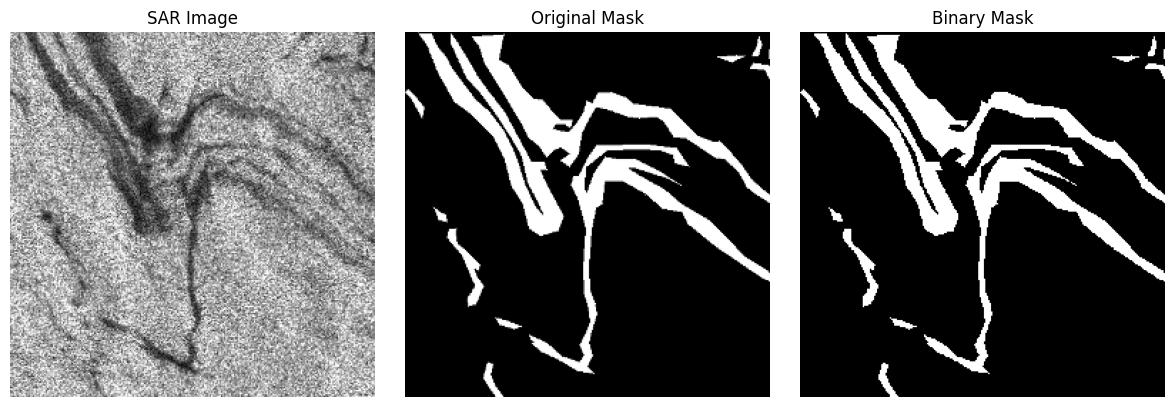

In [8]:
#RERUN

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

image_path = DATA_DIR / "images" / "train" / "palsar_1260.png"
mask_path = DATA_DIR / "masks" / "train" / "palsar_1260.png"

with Image.open(image_path) as im:
    image = np.array(im.convert("RGB"))

with Image.open(mask_path) as im:
    mask = np.array(im.convert("L"))

binary_mask = (mask > 127).astype(np.uint8)

print("Image shape:", image.shape)
print("Mask shape:", binary_mask.shape)
print("Binary mask values:", np.unique(binary_mask))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set_title("SAR Image")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Original Mask")
axes[2].imshow(binary_mask, cmap="gray")
axes[2].set_title("Binary Mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
#RERUN

import torch
import numpy as np

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset, DataLoader


class OilSpillDataset(Dataset):
    def __init__(self, image_dir, mask_dir):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)

        # Match images and masks by filename
        image_names = {p.name for p in self.image_dir.glob("*.png")}
        mask_names = {p.name for p in self.mask_dir.glob("*.png")}

        if image_names != mask_names:
            raise ValueError(
                f"Image-mask mismatch in {self.image_dir}"
            )

        self.names = sorted(image_names)

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        name = self.names[index]

        # Load SAR image as RGB
        with Image.open(self.image_dir / name) as img:
            image = np.array(img.convert("RGB"), dtype=np.float32) / 255.0

        # Load mask as grayscale and convert to binary labels
        with Image.open(self.mask_dir / name) as m:
            mask = np.array(m.convert("L"))

        mask = (mask > 127).astype(np.float32)

        # Convert image from HWC to CHW format
        image = torch.from_numpy(image).permute(2, 0, 1)

        # Add one channel to the mask
        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


# Create training and validation datasets
train_dataset = OilSpillDataset(
    DATA_DIR / "images" / "train",
    DATA_DIR / "masks" / "train"
)

val_dataset = OilSpillDataset(
    DATA_DIR / "images" / "val",
    DATA_DIR / "masks" / "val"
)

# Create batches
train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False, num_workers=2
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Image pixel range:",
      images.min().item(), "to", images.max().item())

print("Mask values:", torch.unique(masks))
print("Spill-labelled pixels in first mask:",
      int(masks[0].sum().item()))

Training samples: 6455
Validation samples: 1615
Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 1, 256, 256])
Image pixel range: 0.0 to 1.0
Mask values: tensor([0., 1.])
Spill-labelled pixels in first mask: 2366


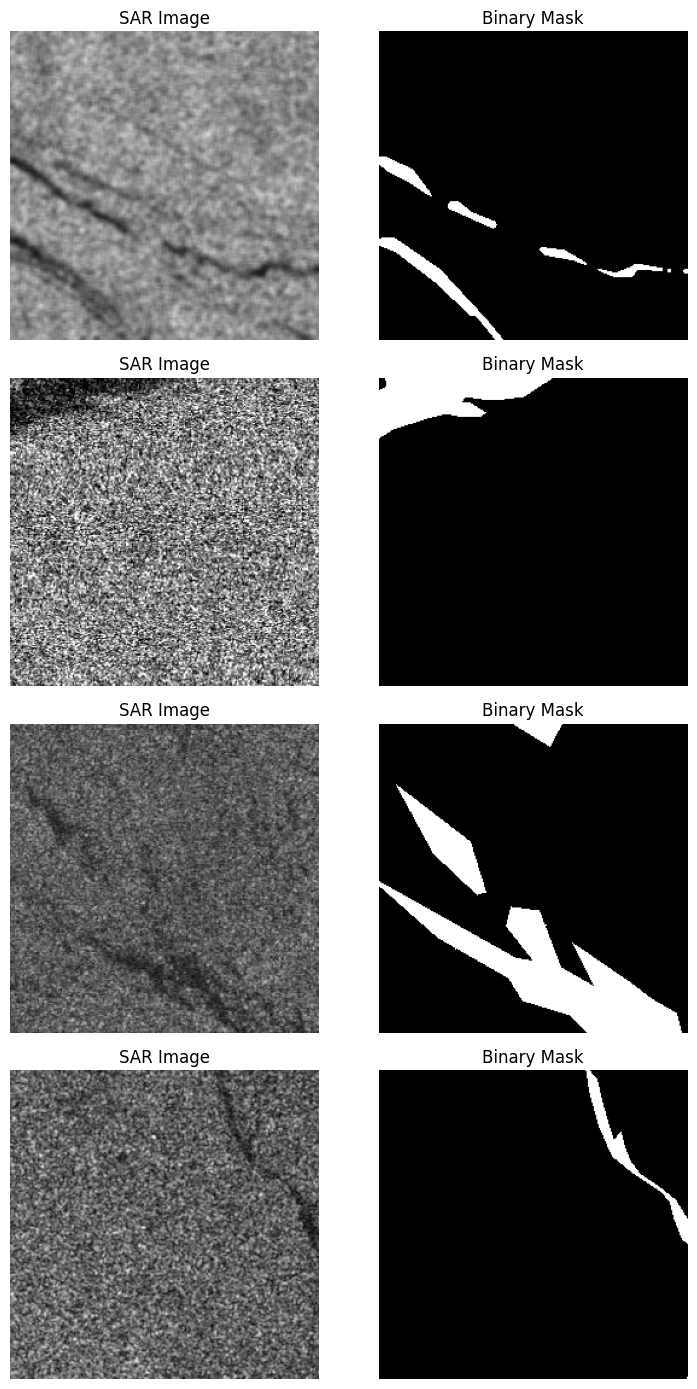

In [10]:
#RERUN

import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(8, 14))

for i in range(4):
    image = images[i].permute(1, 2, 0).numpy()
    mask = masks[i, 0].numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("SAR Image")

    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Binary Mask")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [11]:
#RERUN

import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder: extracts image features
        self.enc1 = DoubleConv(3, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck: deepest feature representation
        self.bottleneck = DoubleConv(256, 512)

        # Decoder: reconstructs the segmentation map
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        # One output channel: probability of the positive class
        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder with skip connections
        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)

In [12]:
#RERUN

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(device)

# Use the batch loaded in the previous step
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    logits = model(images)

print("Device:", device)
print("Input shape:", images.shape)
print("Target mask shape:", masks.shape)
print("Model output shape:", logits.shape)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Device: cuda
Input shape: torch.Size([8, 3, 256, 256])
Target mask shape: torch.Size([8, 1, 256, 256])
Model output shape: torch.Size([8, 1, 256, 256])
Trainable parameters: 7765985


In [ ]:
import torch
import torch.nn as nn

bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits)

    intersection = (probabilities * targets).sum(dim=(1, 2, 3))
    total = probabilities.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + smooth) / (total + smooth)

    return 1 - dice.mean()


def combined_loss(logits, targets):
    return bce_loss(logits, targets) + dice_loss(logits, targets)


def calculate_metrics(logits, targets, threshold=0.5, smooth=1e-7):
    predictions = (torch.sigmoid(logits) >= threshold).float()

    intersection = (predictions * targets).sum(dim=(1, 2, 3))
    pred_total = predictions.sum(dim=(1, 2, 3))
    target_total = targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + smooth) / (
        pred_total + target_total + smooth
    )

    union = pred_total + target_total - intersection
    iou = (intersection + smooth) / (union + smooth)

    return dice.mean().item(), iou.mean().item()


print("Loss functions and metrics defined successfully.")

model.eval()

with torch.no_grad():
    test_logits = model(images)
    test_loss = combined_loss(test_logits, masks)
    test_dice, test_iou = calculate_metrics(test_logits, masks)

print("Initial loss:", round(test_loss.item(), 4))
print("Initial Dice score:", round(test_dice, 4))
print("Initial IoU:", round(test_iou, 4))

Loss functions and metrics defined successfully.
Initial loss: 1.2745
Initial Dice score: 0.0
Initial IoU: 0.0


In [ ]:
import copy
import torch
from pathlib import Path

# Training configuration
EPOCHS = 10
LEARNING_RATE = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = CHECKPOINT_DIR / "unet_best.pth"

best_val_dice = -1.0

for epoch in range(EPOCHS):
    # ---------------- Training ----------------
    model.train()
    train_loss_sum = 0.0

    for batch_images, batch_masks in train_loader:
        batch_images = batch_images.to(device)
        batch_masks = batch_masks.to(device)

        optimizer.zero_grad()

        logits = model(batch_images)
        loss = combined_loss(logits, batch_masks)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item()

    avg_train_loss = train_loss_sum / len(train_loader)

    # ---------------- Validation ----------------
    model.eval()
    val_loss_sum = 0.0
    val_dice_sum = 0.0
    val_iou_sum = 0.0

    with torch.no_grad():
        for batch_images, batch_masks in val_loader:
            batch_images = batch_images.to(device)
            batch_masks = batch_masks.to(device)

            logits = model(batch_images)
            loss = combined_loss(logits, batch_masks)
            dice, iou = calculate_metrics(logits, batch_masks)

            val_loss_sum += loss.item()
            val_dice_sum += dice
            val_iou_sum += iou

    avg_val_loss = val_loss_sum / len(val_loader)
    avg_val_dice = val_dice_sum / len(val_loader)
    avg_val_iou = val_iou_sum / len(val_loader)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Dice: {avg_val_dice:.4f} | "
        f"Val IoU: {avg_val_iou:.4f}"
    )

    # Save best model based on validation Dice
    if avg_val_dice > best_val_dice:
        best_val_dice = avg_val_dice

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_dice": avg_val_dice,
                "val_iou": avg_val_iou,
            },
            BEST_MODEL_PATH
        )

        print(f"  Saved best model: {BEST_MODEL_PATH}")

print("\nTraining complete.")
print("Best validation Dice:", round(best_val_dice, 4))

Epoch 01/10 | Train Loss: 0.4984 | Val Loss: 0.5202 | Val Dice: 0.7901 | Val IoU: 0.6871
  Saved best model: /content/drive/MyDrive/oil_spill_detection/checkpoints/unet_best.pth
Epoch 02/10 | Train Loss: 0.4866 | Val Loss: 0.4831 | Val Dice: 0.7929 | Val IoU: 0.6907
  Saved best model: /content/drive/MyDrive/oil_spill_detection/checkpoints/unet_best.pth
Epoch 03/10 | Train Loss: 0.4792 | Val Loss: 0.5990 | Val Dice: 0.7455 | Val IoU: 0.6341
Epoch 04/10 | Train Loss: 0.4841 | Val Loss: 0.5080 | Val Dice: 0.7916 | Val IoU: 0.6904
Epoch 05/10 | Train Loss: 0.4798 | Val Loss: 0.5318 | Val Dice: 0.7764 | Val IoU: 0.6716
Epoch 06/10 | Train Loss: 0.4739 | Val Loss: 0.5144 | Val Dice: 0.7808 | Val IoU: 0.6775
Epoch 07/10 | Train Loss: 0.4662 | Val Loss: 0.4574 | Val Dice: 0.8012 | Val IoU: 0.7009
  Saved best model: /content/drive/MyDrive/oil_spill_detection/checkpoints/unet_best.pth
Epoch 08/10 | Train Loss: 0.4644 | Val Loss: 0.4639 | Val Dice: 0.8027 | Val IoU: 0.7012
  Saved best model: /

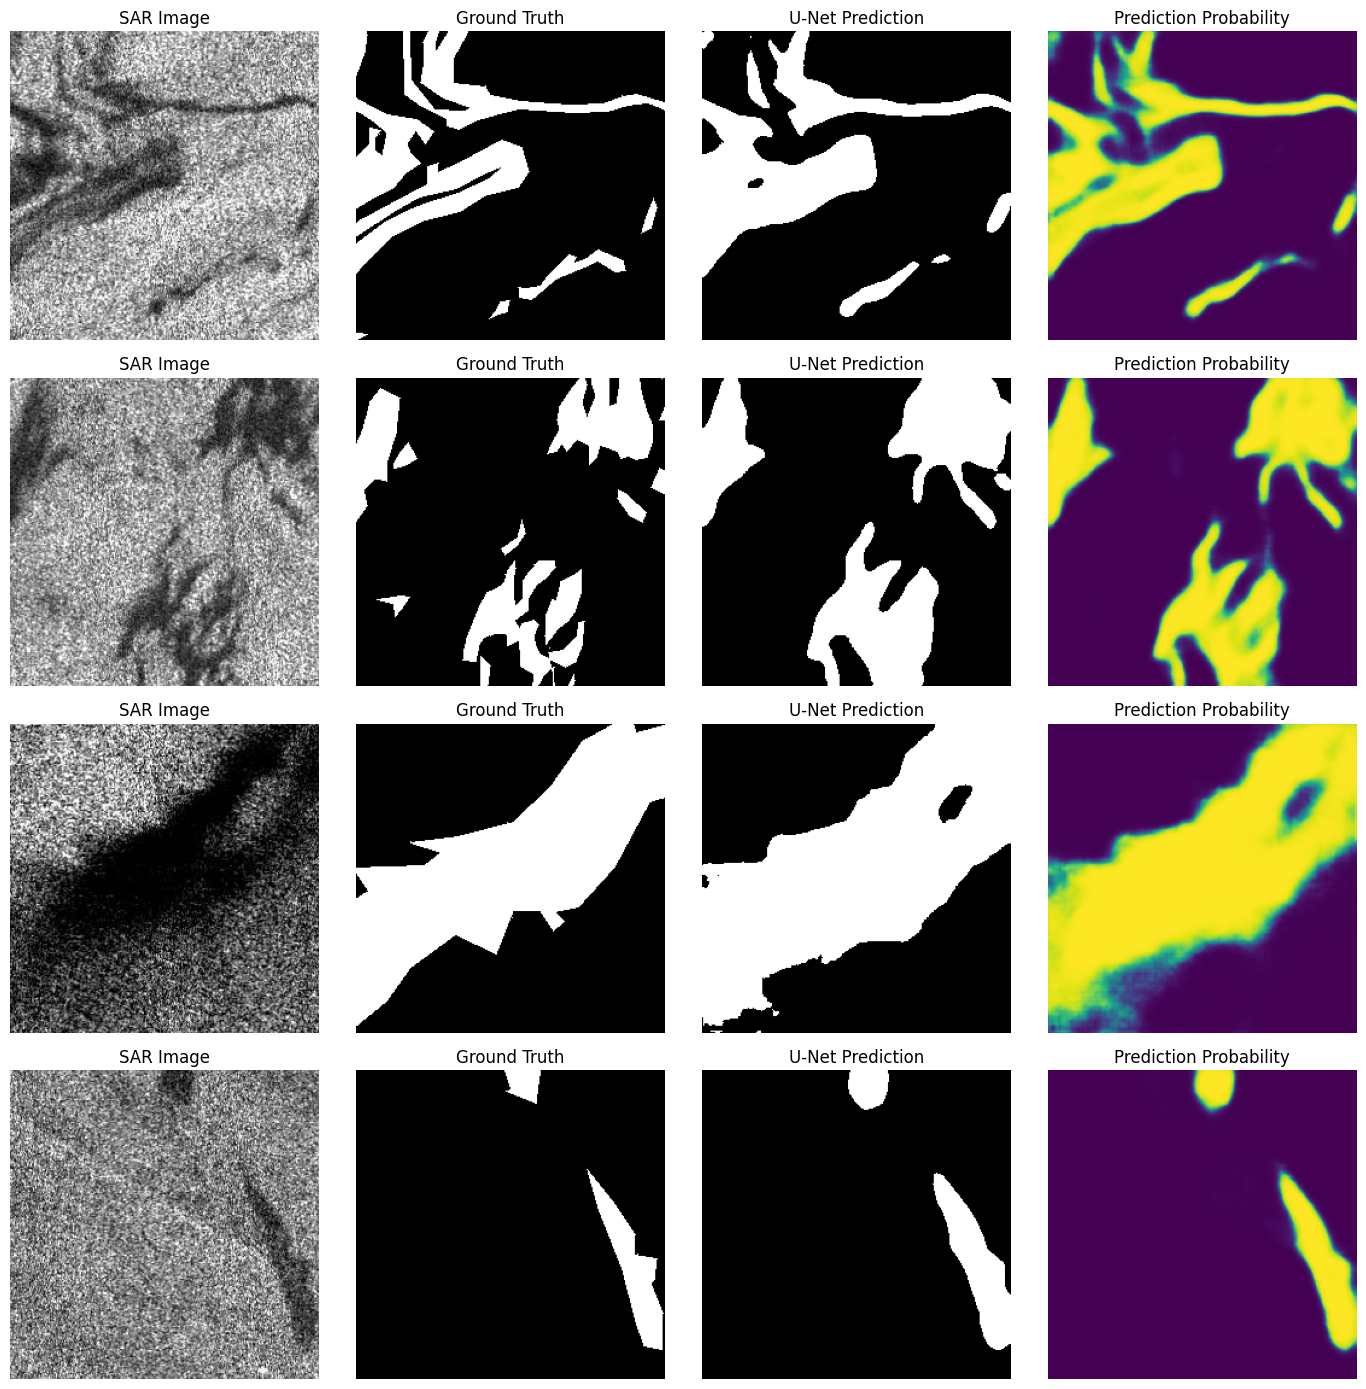

Loaded checkpoint from epoch: 8
Saved validation Dice: 0.8027
Saved validation IoU: 0.7012


In [13]:
#RERUN

import torch
import numpy as np
import matplotlib.pyplot as plt

# Load the best saved checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Get one validation batch
val_images, val_masks = next(iter(val_loader))
val_images = val_images.to(device)
val_masks = val_masks.to(device)

with torch.no_grad():
    logits = model(val_images)
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= 0.5).float()

# Display four validation examples
fig, axes = plt.subplots(4, 4, figsize=(14, 14))

for i in range(4):
    image = val_images[i].cpu().permute(1, 2, 0).numpy()
    true_mask = val_masks[i, 0].cpu().numpy()
    pred_mask = predictions[i, 0].cpu().numpy()
    prob_map = probabilities[i, 0].cpu().numpy()

    axes[i, 0].imshow(image)
    axes[i, 0].set_title("SAR Image")

    axes[i, 1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(pred_mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title("U-Net Prediction")

    axes[i, 3].imshow(prob_map, cmap="viridis", vmin=0, vmax=1)
    axes[i, 3].set_title("Prediction Probability")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("Loaded checkpoint from epoch:", checkpoint["epoch"])
print("Saved validation Dice:", round(checkpoint["val_dice"], 4))
print("Saved validation IoU:", round(checkpoint["val_iou"], 4))

In [14]:
import torch

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

# Accumulate intersection and pixel counts over the full validation set
results = {
    t: {"intersection": 0, "pred": 0, "target": 0}
    for t in thresholds
}

model.eval()

with torch.no_grad():
    for batch_images, batch_masks in val_loader:
        batch_images = batch_images.to(device)
        batch_masks = batch_masks.to(device)

        probabilities = torch.sigmoid(model(batch_images))

        for t in thresholds:
            predictions = (probabilities >= t).float()

            results[t]["intersection"] += (
                predictions * batch_masks
            ).sum().item()

            results[t]["pred"] += predictions.sum().item()
            results[t]["target"] += batch_masks.sum().item()

print("Threshold | Dice     | IoU")
print("-" * 31)

for t in thresholds:
    r = results[t]
    intersection = r["intersection"]
    pred_pixels = r["pred"]
    target_pixels = r["target"]

    dice = (2 * intersection) / max(pred_pixels + target_pixels, 1)
    iou = intersection / max(pred_pixels + target_pixels - intersection, 1)

    print(f"{t:9.2f} | {dice:.4f}   | {iou:.4f}")

Threshold | Dice     | IoU
-------------------------------
     0.30 | 0.8441   | 0.7303
     0.35 | 0.8481   | 0.7363
     0.40 | 0.8513   | 0.7412
     0.45 | 0.8538   | 0.7449
     0.50 | 0.8555   | 0.7474
     0.55 | 0.8563   | 0.7487
     0.60 | 0.8561   | 0.7484
     0.65 | 0.8541   | 0.7454
     0.70 | 0.8492   | 0.7379


In [15]:
import json
from pathlib import Path

results_path = RESULTS_PATH

summary = {
    "model": "U-Net",
    "dataset": "Refined Deep-SAR Oil Spill (SOS)",
    "training_epochs": 10,
    "best_checkpoint_epoch": 8,
    "best_validation_dice_per_image": 0.8027,
    "best_validation_iou_per_image": 0.7012,
    "best_global_threshold": 0.55,
    "best_global_dice": 0.8563,
    "best_global_iou": 0.7487
}

with open(results_path, "w") as f:
    json.dump(summary, f, indent=4)

print("Baseline results saved to:", results_path)

Baseline results saved to: /content/drive/MyDrive/oil_spill_detection/phase1_results.json


In [16]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path
from google.colab import files

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the best saved checkpoint
checkpoint_path = BEST_MODEL_PATH

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

# Prediction threshold selected during validation
THRESHOLD = 0.55

print("Model loaded successfully!")
print("Device:", device)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Prediction threshold:", THRESHOLD)

Model loaded successfully!
Device: cuda
Checkpoint epoch: 8
Prediction threshold: 0.55


Selected image: palsar_0.png


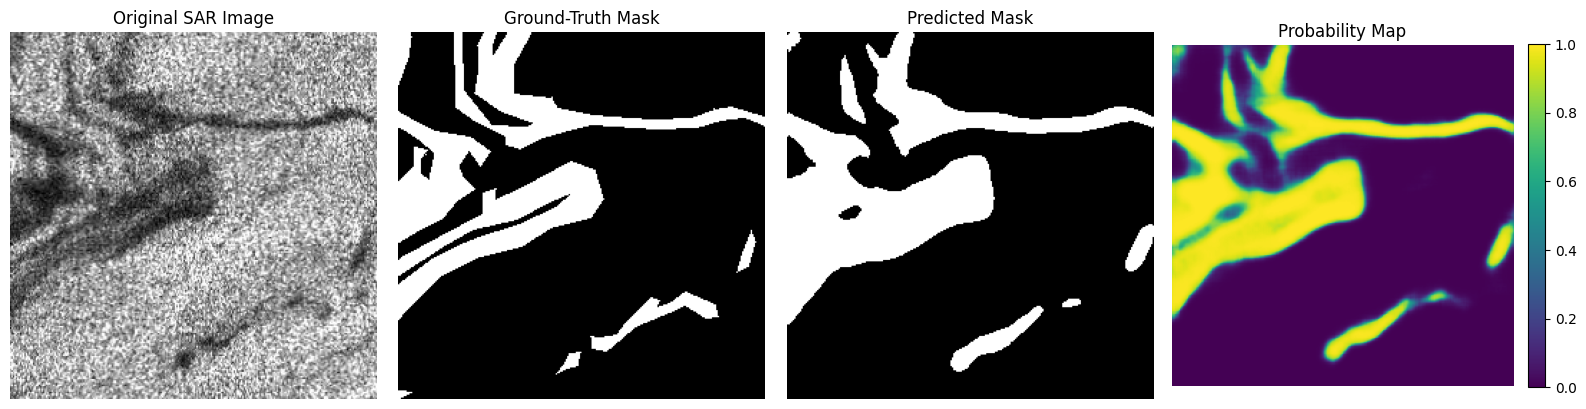

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

# Define validation folders
image_dir = DATA_DIR / "images" / "val"
mask_dir = DATA_DIR / "masks" / "val"

# Find matching image-mask pairs
image_paths = sorted(image_dir.glob("*.png"))

if not image_paths:
    raise FileNotFoundError(
        f"No PNG images found in {image_dir}. "
        "Check whether your dataset is extracted."
    )

image_path = next(
    (p for p in image_paths if (mask_dir / p.name).exists()),
    None
)

if image_path is None:
    raise FileNotFoundError("No matching image-mask pair found.")

mask_path = mask_dir / image_path.name

print("Selected image:", image_path.name)

# Load and preprocess image
image = Image.open(image_path).convert("RGB")
image_array = np.array(image, dtype=np.float32) / 255.0

image_tensor = torch.from_numpy(image_array)
image_tensor = image_tensor.permute(2, 0, 1).unsqueeze(0).to(device)

# Generate prediction
model.eval()
with torch.no_grad():
    logits = model(image_tensor)
    probability_map = torch.sigmoid(logits)[0, 0].cpu().numpy()

predicted_mask = (probability_map >= THRESHOLD).astype(np.uint8)

# Load reference mask
ground_truth = np.array(Image.open(mask_path).convert("L"))
ground_truth = (ground_truth > 127).astype(np.uint8)

# Display all four results
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(image_array)
axes[0].set_title("Original SAR Image")

axes[1].imshow(ground_truth, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Ground-Truth Mask")

axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Predicted Mask")

im = axes[3].imshow(
    probability_map, cmap="viridis", vmin=0, vmax=1
)
axes[3].set_title("Probability Map")
plt.colorbar(im, ax=axes[3], fraction=0.046, pad=0.04)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Calculate metrics for the displayed image
intersection = np.sum(predicted_mask * ground_truth)

predicted_pixels = np.sum(predicted_mask)
actual_pixels = np.sum(ground_truth)

dice = (2 * intersection) / max(
    predicted_pixels + actual_pixels, 1
)

union = predicted_pixels + actual_pixels - intersection
iou = intersection / max(union, 1)

print(f"Dice Score: {dice:.4f}")
print(f"IoU Score:  {iou:.4f}")

Dice Score: 0.8178
IoU Score:  0.6918


In [ ]:
!pip install gradio -q

In [17]:
import gradio as gr
import numpy as np
import torch
from PIL import Image

def predict_oil_spill(input_image):
    if input_image is None:
        return None, None

    # Convert uploaded image to RGB and resize to model input size
    image = input_image.convert("RGB").resize((256, 256))
    image_array = np.array(image, dtype=np.float32) / 255.0

    # Convert image to a PyTorch tensor
    image_tensor = torch.from_numpy(image_array)
    image_tensor = image_tensor.permute(2, 0, 1).unsqueeze(0).to(device)

    # Generate prediction
    model.eval()
    with torch.no_grad():
        logits = model(image_tensor)
        probability_map = torch.sigmoid(logits)[0, 0].cpu().numpy()

    # Create binary segmentation mask
    predicted_mask = (probability_map >= THRESHOLD).astype(np.uint8) * 255

    # Return mask and probability map
    mask_image = Image.fromarray(predicted_mask)

    probability_image = Image.fromarray(
        (probability_map * 255).astype(np.uint8)
    )

    return mask_image, probability_image


# Build the interface
app = gr.Interface(
    fn=predict_oil_spill,
    inputs=gr.Image(type="pil", label="Upload SAR Image"),
    outputs=[
        gr.Image(type="pil", label="Predicted Segmentation Mask"),
        gr.Image(type="pil", label="Probability Map")
    ],
    title="Oil Spill Detection using U-Net",
    description=(
        "Upload a SAR image to generate a pixel-level segmentation prediction. "
        "White pixels indicate the model's predicted positive class. "
        "The probability map shows the model's output confidence per pixel."
    )
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://12bce09c1790da6022.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
